## Clean dataset

In [1]:
import pandas as pd

my1 = pd.read_csv("../data/processed/malaysia_cleaned.csv")

In [2]:
ls ../data/processed

clean_sg_part_a_yihan.csv   malaysia_part_a_jianru.csv
clean_sg_part_b_junhui.csv  malaysia_part_b_sutong.csv
malaysia_cleaned.csv


In [4]:
# Recode men as 0, women as 1 (make men the reference group)
my1["gender_bi"] = my1["gender_cat"].map(
    {
        1:0,
        2:1
    }
)

In [5]:
my1 = my1.drop(columns="gender_cat")

In [6]:
# Rename Q131_cat as security
my1 = my1.rename(
    columns={"Q131_cat":"security"}
)

# Rename Q138_cat as harrassment
my1 = my1.rename(
    columns={"Q138_cat":"harrassment"}
)

In [7]:
main_vars = ["security", "harrassment", "gender_bi"]

my1[main_vars].info() #to see how many non-missing observations, and what are the data types

<class 'pandas.DataFrame'>
RangeIndex: 1313 entries, 0 to 1312
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   security     1313 non-null   int64
 1   harrassment  1313 non-null   int64
 2   gender_bi    1313 non-null   int64
dtypes: int64(3)
memory usage: 30.9 KB


In [8]:
# Reverse code security and harassment to make the value more align to their name
my1["security_r"] = 5 - my1["security"]  # Reverse-code security: higher = more secure
my1["harrassment_r"] = 5 - my1["harrassment"]  # Reverse-code harrassment: higher = more frequent harrassment

In [9]:
# Rename Q262 into Age
my1 = my1.rename(columns={"Q262": "age"})

In [10]:
print(my1.columns.tolist())

['D_INTERVIEW', 'edu', 'household_income', 'em', 'marriage', 'victim_self', 'victim_family', 'security', 'harrassment', 'age', 'gender_bi', 'security_r', 'harrassment_r']


## Malaysia Regression

In [3]:
import pandas as pd
import numpy as np
from plotnine import *
import warnings
warnings.filterwarnings('ignore')
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

In [11]:
from stargazer.stargazer import Stargazer

In [12]:
# Select variables used in the regression
reg_vars = [
    "security_r",
    "harrassment_r",
    "gender_bi",
    "age",
    "edu",
    "household_income",
    "em",
    "marriage",
    "victim_self",
    "victim_family"
]
reg_df = my1[reg_vars].dropna().copy()

## Model 2

In [13]:
ols_model2 = smf.ols(
    'security_r ~ harrassment_r + gender_bi + age + edu + household_income + em + marriage + victim_self + victim_family', data=my1).fit()

print(ols_model2.summary())

                            OLS Regression Results                            
Dep. Variable:             security_r   R-squared:                       0.174
Model:                            OLS   Adj. R-squared:                  0.168
Method:                 Least Squares   F-statistic:                     30.41
Date:                Wed, 28 Oct 2026   Prob (F-statistic):           1.57e-48
Time:                        21:25:32   Log-Likelihood:                -1326.5
No. Observations:                1313   AIC:                             2673.
Df Residuals:                    1303   BIC:                             2725.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            3.6951      0.092  

## Forest map

In [14]:
import pandas as pd
from plotnine import (
    ggplot, aes, geom_point, geom_segment,
    geom_vline, labs, theme_minimal)

In [15]:
# Extract the coefficients
ci = ols_model2.conf_int()

In [16]:
# Extract 95% confidence intervals
coef_df = pd.DataFrame({
    "Variable": ols_model2.params.index,
    "Coefficient": ols_model2.params.values,
    "Lower": ci.iloc[:, 0].values,
    "Upper": ci.iloc[:, 1].values
})

In [17]:
# Don't display the intercept
coef_df = coef_df[coef_df["Variable"] != "Intercept"].copy()

In [18]:
# Arrange the order of variables, keep same with model
coef_df["Variable"] = pd.Categorical(
    coef_df["Variable"],
    categories=coef_df["Variable"].tolist()[::-1],
    ordered=True
)

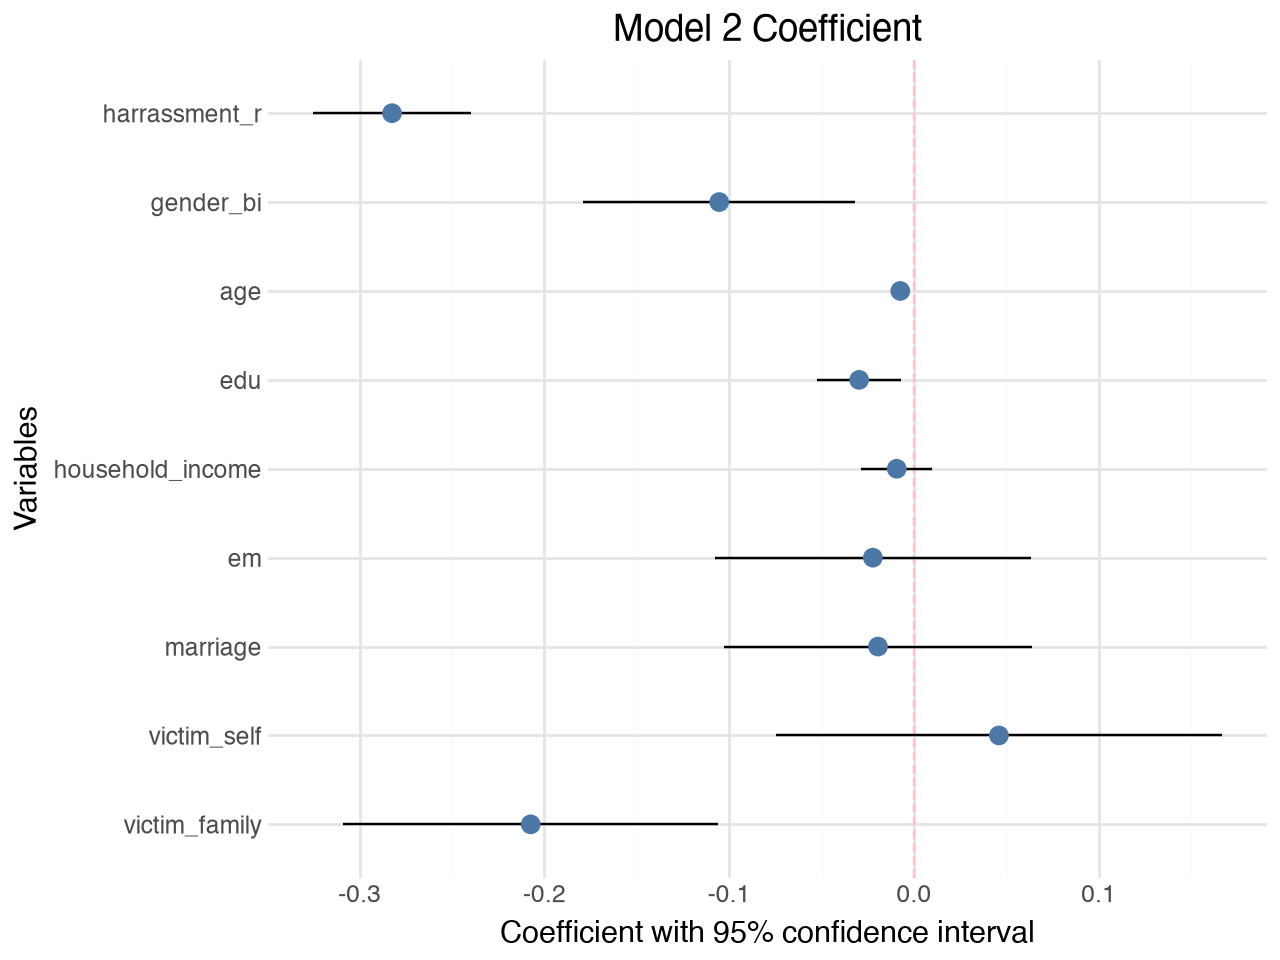

In [19]:
# Forest plot
(
    ggplot(coef_df, aes(x="Coefficient", y="Variable"))
    + geom_vline(xintercept=0, linetype="dashed", color="pink")
    + geom_segment(aes(x="Lower", xend="Upper", yend="Variable"))
    + geom_point(size=3, color="#4C78A8")
    + theme_minimal()
    + labs(
        title="Model 2 Coefficient",
        x="Coefficient with 95% confidence interval",
        y="Variables"
    )
)